

This notebook contains the shared preprocessing pipeline and final implementations
of all three supervised learning algorithms. All models use the same training/test
split, cross-validation framework, imbalance treatment, and evaluation metrics to
support a controlled comparison.

## Reproducibility and Runtime Note

All models use a fixed random state of 42 where supported. Full execution of this
notebook may require approximately 30–45 minutes depending on available hardware.
The Random Forest randomized hyperparameter search is the most computationally
intensive step because it evaluates 25 candidate configurations using five-fold
cross-validation.

# Shared Data Preparation and Experimental Framework

**Author:Marco Mihajlovic

This section defines the common dataset loading, feature/target separation,
stratified train/test split, preprocessing pipeline, class-imbalance treatment,
and five-fold cross-validation strategy used by all three model implementations.

In [1]:
# ============================================================
# 1. SHARED IMPORTS AND CONFIGURATION
# ============================================================

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict
)

from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve
)

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42

In [2]:
# ============================================================
# SHARED MODEL EVALUATION UTILITIES
# ============================================================

def evaluate_classifier(y_true, probabilities, threshold=0.5):
    """
    Evaluate binary classifier probability predictions at a
    specified decision threshold.

    Parameters
    ----------
    y_true : array-like
        Ground-truth binary class labels.
    probabilities : array-like
        Predicted probabilities for the positive (fraud) class.
    threshold : float, default=0.5
        Probability cutoff used to assign class predictions.

    Returns
    -------
    results : dict
        PR-AUC, ROC-AUC, Accuracy, Precision, Recall, and F1.
    predictions : ndarray
        Binary predictions produced at the specified threshold.
    """
    predictions = (probabilities >= threshold).astype(int)

    results = {
        "PR-AUC": average_precision_score(y_true, probabilities),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1": f1_score(y_true, predictions)
    }

    return results, predictions


def select_recall_constrained_threshold(
    y_true,
    probabilities,
    min_recall=0.80
):
    """
    Select the probability threshold that maximizes precision
    while maintaining recall at or above a specified minimum.

    Threshold selection is performed on out-of-fold training
    probabilities so that the held-out test set remains unseen.

    Returns
    -------
    threshold : float
        Selected operating threshold.
    precision_at_threshold : float
        Precision achieved on the OOF predictions.
    recall_at_threshold : float
        Recall achieved on the OOF predictions.
    """
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    # precision_recall_curve returns one more precision/recall
    # value than threshold values.
    precision = precision[:-1]
    recall = recall[:-1]

    valid = recall >= min_recall

    if not np.any(valid):
        raise ValueError(
            f"No threshold achieved recall >= {min_recall:.2f}"
        )

    valid_indices = np.where(valid)[0]
    best_idx = valid_indices[
        np.argmax(precision[valid])
    ]

    return (
        thresholds[best_idx],
        precision[best_idx],
        recall[best_idx]
    )

In [3]:
# ============================================================
# 2. LOAD FULL DATASET
# ============================================================

from pathlib import Path

DATA_PATH = Path("creditcard.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "creditcard.csv was not found. Place creditcard.csv in the "
        "same folder as this notebook before running."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")
print(f"Total transactions: {len(df):,}")
print(f"Fraudulent transactions: {df['Class'].sum():,}")
print(f"Fraud percentage: {df['Class'].mean() * 100:.4f}%")

df.head()

Dataset loaded successfully.
Dataset shape: (284807, 31)
Total transactions: 284,807
Fraudulent transactions: 492
Fraud percentage: 0.1727%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# ============================================================
# DEFINE FEATURES AND TARGET
# ============================================================

X = df.drop(columns="Class")
y = df["Class"]

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)

Feature matrix: (284807, 30)
Target vector: (284807,)


In [5]:
# ============================================================
# SHARED TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Training observations: {len(X_train):,}")
print(f"Testing observations:  {len(X_test):,}")

print(f"\nTraining fraud count: {y_train.sum():,}")
print(f"Testing fraud count:  {y_test.sum():,}")

print(f"\nTraining fraud rate: {y_train.mean() * 100:.4f}%")
print(f"Testing fraud rate:  {y_test.mean() * 100:.4f}%")

Training observations: 227,845
Testing observations:  56,962

Training fraud count: 394
Testing fraud count:  98

Training fraud rate: 0.1729%
Testing fraud rate:  0.1720%


In [6]:
# ============================================================
# SHARED PREPROCESSING
# ============================================================

from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer

scaled_features = ["Time", "Amount"]

pca_features = [
    col for col in X.columns
    if col not in scaled_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("robust_scale", RobustScaler(), scaled_features),
        ("pca_passthrough", "passthrough", pca_features)
    ],
    remainder="drop"
)

print("Scaled features:", scaled_features)
print("Passthrough PCA features:", len(pca_features))

Scaled features: ['Time', 'Amount']
Passthrough PCA features: 28


In [7]:
# ============================================================
# SHARED IMBALANCE TREATMENT + CROSS-VALIDATION
# ============================================================

from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import StratifiedKFold

oversampler = RandomOverSampler(
    random_state=RANDOM_STATE
)

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(oversampler)
print(cv_strategy)

RandomOverSampler(random_state=42)
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


# Logistic Regression Implementation

Logistic Regression is evaluated as the linear baseline classifier in this study.
The implementation uses the shared full dataset, preprocessing pipeline, class-imbalance
treatment, cross-validation strategy, and held-out test set defined above so that its
performance can be compared directly with the Random Forest and Artificial Neural
Network models.

In [8]:
# ============================================================
# LOGISTIC REGRESSION HYPERPARAMETER TUNING
# ============================================================

from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("oversampler", RandomOverSampler(
        random_state=RANDOM_STATE
    )),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        penalty="l2",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

lr_param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1.0, 10.0]
}

lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="average_precision",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

print("Starting Logistic Regression Grid Search...")
lr_grid_search.fit(X_train, y_train)

print("\nBEST LOGISTIC REGRESSION PARAMETERS")
print("-" * 45)
print(lr_grid_search.best_params_)

print("\nBest CV PR-AUC:")
print(f"{lr_grid_search.best_score_:.4f}")

Starting Logistic Regression Grid Search...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

BEST LOGISTIC REGRESSION PARAMETERS
---------------------------------------------
{'classifier__C': 0.1}

Best CV PR-AUC:
0.7567


In [9]:
# ============================================================
# LOGISTIC REGRESSION — HYPERPARAMETER TUNING RESULTS
# ============================================================

lr_tuning_results = pd.DataFrame(
    lr_grid_search.cv_results_
)[[
    "param_classifier__C",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

lr_tuning_results = lr_tuning_results.rename(columns={
    "param_classifier__C": "C",
    "mean_test_score": "Mean CV PR-AUC",
    "std_test_score": "CV PR-AUC Std",
    "rank_test_score": "Rank"
})

lr_tuning_results = lr_tuning_results.sort_values("Rank")

print("LOGISTIC REGRESSION TUNING RESULTS")
print("-" * 45)

lr_tuning_results.round(6)

LOGISTIC REGRESSION TUNING RESULTS
---------------------------------------------


,C,Mean CV PR-AUC,CV PR-AUC Std,Rank
2,0.100,0.756727,0.051630,1
4,10.000,0.756715,0.051371,2
3,1.000,0.756685,0.051404,3
1,0.010,0.756584,0.052034,4
0,0.001,0.737218,0.059581,5


In [10]:
# ============================================================
# LOGISTIC REGRESSION — DEFAULT THRESHOLD EVALUATION
# ============================================================

lr_tuned_model = lr_grid_search.best_estimator_

# Probability predictions on held-out test set
lr_tuned_proba = lr_tuned_model.predict_proba(X_test)[:, 1]

# Standardized evaluation at the default 0.5 threshold
lr_default_results, lr_tuned_pred = evaluate_classifier(
    y_test,
    lr_tuned_proba,
    threshold=0.5
)

print("TUNED LOGISTIC REGRESSION — DEFAULT THRESHOLD")
print("-" * 55)

for metric, value in lr_default_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_tuned_pred))

TUNED LOGISTIC REGRESSION — DEFAULT THRESHOLD
-------------------------------------------------------
PR-AUC: 0.7111
ROC-AUC: 0.9720
Accuracy: 0.9757
Precision: 0.0613
Recall: 0.9184
F1: 0.1149

Confusion Matrix:
[[55485  1379]
 [    8    90]]


In [11]:
# ============================================================
# LOGISTIC REGRESSION — OOF THRESHOLD SELECTION
# Goal: maximize precision while maintaining recall >= 0.80
# ============================================================

print("Generating Logistic Regression out-of-fold probabilities...")

lr_oof_proba = cross_val_predict(
    lr_tuned_model,
    X_train,
    y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions complete.")
print(f"OOF PR-AUC: {average_precision_score(y_train, lr_oof_proba):.4f}")
print(f"Number of OOF predictions: {len(lr_oof_proba):,}")

Generating Logistic Regression out-of-fold probabilities...
Out-of-fold predictions complete.
OOF PR-AUC: 0.7441
Number of OOF predictions: 227,845


In [12]:
# ============================================================
# SELECT LOGISTIC REGRESSION OPERATING THRESHOLD
# ============================================================

lr_optimal_threshold, lr_oof_precision, lr_oof_recall = (
    select_recall_constrained_threshold(
        y_train,
        lr_oof_proba,
        min_recall=0.80
    )
)

print("LOGISTIC REGRESSION THRESHOLD SELECTION")
print("-" * 50)
print("Selection rule: Maximum precision with recall >= 0.80")
print(f"Selected threshold: {lr_optimal_threshold:.6f}")
print(f"OOF precision at threshold: {lr_oof_precision:.4f}")
print(f"OOF recall at threshold:    {lr_oof_recall:.4f}")

LOGISTIC REGRESSION THRESHOLD SELECTION
--------------------------------------------------
Selection rule: Maximum precision with recall >= 0.80
Selected threshold: 0.999801
OOF precision at threshold: 0.7349
OOF recall at threshold:    0.8020


In [13]:
# ============================================================
# LOGISTIC REGRESSION — OPTIMIZED THRESHOLD TEST EVALUATION
# ============================================================

lr_optimized_results, lr_optimized_pred = evaluate_classifier(
    y_test,
    lr_tuned_proba,
    threshold=lr_optimal_threshold
)

print("TUNED LOGISTIC REGRESSION — OPTIMIZED THRESHOLD")
print("-" * 60)
print(f"Threshold: {lr_optimal_threshold:.6f}")

for metric, value in lr_optimized_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_optimized_pred))

TUNED LOGISTIC REGRESSION — OPTIMIZED THRESHOLD
------------------------------------------------------------
Threshold: 0.999801
PR-AUC: 0.7111
ROC-AUC: 0.9720
Accuracy: 0.9991
Precision: 0.7009
Recall: 0.8367
F1: 0.7628

Confusion Matrix:
[[56829    35]
 [   16    82]]


In [14]:
# ============================================================
# LOGISTIC REGRESSION TRAINING AND PREDICTION TIME
# ============================================================

from sklearn.base import clone

lr_timing_model = clone(lr_tuned_model)

start_train = time.perf_counter()
lr_timing_model.fit(X_train, y_train)
lr_training_time = time.perf_counter() - start_train

start_predict = time.perf_counter()
lr_timing_proba = lr_timing_model.predict_proba(X_test)[:, 1]
lr_prediction_time = time.perf_counter() - start_predict

print(f"Training time:   {lr_training_time:.4f} seconds")
print(f"Prediction time: {lr_prediction_time:.4f} seconds")

Training time:   1.6338 seconds
Prediction time: 0.0096 seconds


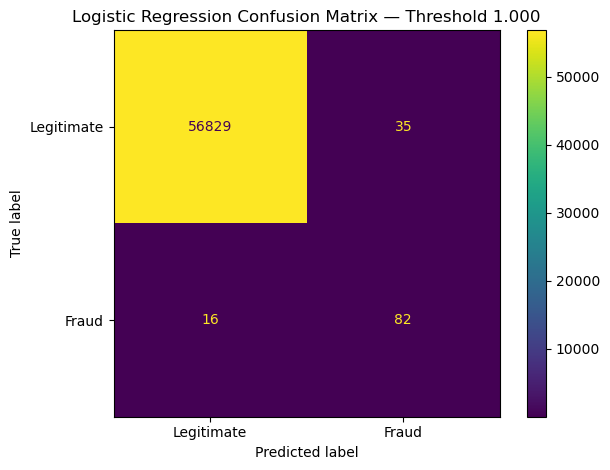

In [15]:
# ============================================================
# LOGISTIC REGRESSION CONFUSION MATRIX — OPTIMIZED THRESHOLD
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_optimized_pred,
    display_labels=["Legitimate", "Fraud"],
    values_format="d"
)

plt.title(
    f"Logistic Regression Confusion Matrix — Threshold {lr_optimal_threshold:.3f}"
)
plt.tight_layout()
plt.show()

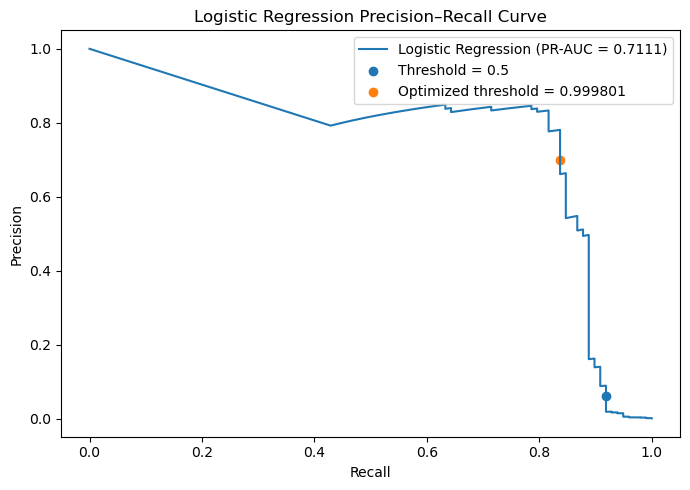

In [16]:
# ============================================================
# LOGISTIC REGRESSION PRECISION–RECALL CURVE
# ============================================================

lr_precision_test, lr_recall_test, _ = precision_recall_curve(
    y_test,
    lr_tuned_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    lr_recall_test,
    lr_precision_test,
    label=f"Logistic Regression (PR-AUC = {lr_default_results['PR-AUC']:.4f})"
)

plt.scatter(
    lr_default_results["Recall"],
    lr_default_results["Precision"],
    label="Threshold = 0.5"
)

plt.scatter(
    lr_optimized_results["Recall"],
    lr_optimized_results["Precision"],
    label=f"Optimized threshold = {lr_optimal_threshold:.6f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression Precision–Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

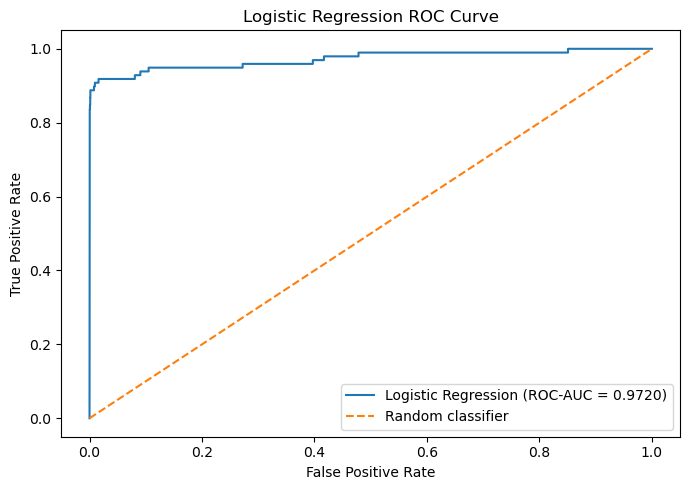

In [17]:
# ============================================================
# LOGISTIC REGRESSION ROC CURVE
# ============================================================

lr_fpr, lr_tpr, _ = roc_curve(
    y_test,
    lr_tuned_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (ROC-AUC = {lr_default_results['ROC-AUC']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# LOGISTIC REGRESSION FINAL SUMMARY TABLE
# ============================================================

lr_summary = pd.DataFrame({
    "Tuned LR (0.5)": [
        lr_default_results["PR-AUC"],
        lr_default_results["ROC-AUC"],
        lr_default_results["Accuracy"],
        lr_default_results["Precision"],
        lr_default_results["Recall"],
        lr_default_results["F1"]
    ],
    "Tuned LR (Optimized Threshold)": [
        lr_optimized_results["PR-AUC"],
        lr_optimized_results["ROC-AUC"],
        lr_optimized_results["Accuracy"],
        lr_optimized_results["Precision"],
        lr_optimized_results["Recall"],
        lr_optimized_results["F1"]
    ]
}, index=[
    "PR-AUC",
    "ROC-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
])

lr_summary.round(4)

,Tuned LR (0.5),Tuned LR (Optimized Threshold)
PR-AUC,0.7111,0.7111
ROC-AUC,0.9720,0.9720
Accuracy,0.9757,0.9991
Precision,0.0613,0.7009
Recall,0.9184,0.8367
F1,0.1149,0.7628


# Random Forest Implementation


The Random Forest implementation uses the shared preprocessing,
class-imbalance treatment, five-fold cross-validation framework, and
held-out test set defined above.

In [19]:
# ============================================================
# RANDOM FOREST BASELINE
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

rf_baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("oversampler", oversampler),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_baseline_pipeline.fit(X_train, y_train)

# Probability predictions for ranking metrics
rf_baseline_proba = rf_baseline_pipeline.predict_proba(X_test)[:, 1]

# Default 0.5 threshold predictions
rf_baseline_pred = (rf_baseline_proba >= 0.5).astype(int)

baseline_results = {
    "PR-AUC": average_precision_score(y_test, rf_baseline_proba),
    "ROC-AUC": roc_auc_score(y_test, rf_baseline_proba),
    "Accuracy": accuracy_score(y_test, rf_baseline_pred),
    "Precision": precision_score(y_test, rf_baseline_pred),
    "Recall": recall_score(y_test, rf_baseline_pred),
    "F1": f1_score(y_test, rf_baseline_pred)
}

print("BASELINE RANDOM FOREST RESULTS")
print("-" * 40)

for metric, value in baseline_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_baseline_pred))

BASELINE RANDOM FOREST RESULTS
----------------------------------------
PR-AUC: 0.8675
ROC-AUC: 0.9525
Accuracy: 0.9996
Precision: 0.9512
Recall: 0.7959
F1: 0.8667

Confusion Matrix:
[[56860     4]
 [   20    78]]


In [20]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("oversampler", RandomOverSampler(
        random_state=RANDOM_STATE
    )),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="average_precision",
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

rf_random_search.fit(X_train, y_train)

print("\nBEST RANDOM FOREST PARAMETERS")
print("-" * 40)
print(rf_random_search.best_params_)

print("\nBest CV PR-AUC:")
print(f"{rf_random_search.best_score_:.4f}")

Fitting 5 folds for each of 25 candidates, totalling 125 fits

BEST RANDOM FOREST PARAMETERS
----------------------------------------
{'classifier__n_estimators': 500, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 30}

Best CV PR-AUC:
0.8500


In [21]:
# ============================================================
# RANDOM FOREST — HYPERPARAMETER TUNING RESULTS
# ============================================================

rf_tuning_results = pd.DataFrame(
    rf_random_search.cv_results_
)[[
    "param_classifier__n_estimators",
    "param_classifier__max_depth",
    "param_classifier__max_features",
    "param_classifier__min_samples_split",
    "param_classifier__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

rf_tuning_results = rf_tuning_results.rename(columns={
    "param_classifier__n_estimators": "n_estimators",
    "param_classifier__max_depth": "max_depth",
    "param_classifier__max_features": "max_features",
    "param_classifier__min_samples_split": "min_samples_split",
    "param_classifier__min_samples_leaf": "min_samples_leaf",
    "mean_test_score": "Mean CV PR-AUC",
    "std_test_score": "CV PR-AUC Std",
    "rank_test_score": "Rank"
})

rf_tuning_results = rf_tuning_results.sort_values("Rank")

print("TOP RANDOM FOREST TUNING RESULTS")
print("-" * 45)

rf_tuning_results.head(10).round(6)

TOP RANDOM FOREST TUNING RESULTS
---------------------------------------------


,n_estimators,max_depth,max_features,min_samples_split,min_samples_leaf,Mean CV PR-AUC,CV PR-AUC Std,Rank
20,500,30,log2,2,2,0.849995,0.020760,1
10,300,30,sqrt,5,1,0.847444,0.021058,2
18,200,30,sqrt,10,2,0.846857,0.019229,3
16,200,None,sqrt,5,1,0.846444,0.020938,4
5,200,None,sqrt,10,1,0.846444,0.020938,4
9,500,20,log2,2,2,0.846049,0.018235,6
6,300,None,log2,10,1,0.844750,0.020842,7
3,300,None,log2,5,1,0.844750,0.020842,7
13,500,30,log2,2,4,0.844578,0.018615,9
23,300,30,log2,10,4,0.844398,0.018534,10


In [22]:
# ============================================================
# EVALUATE TUNED RANDOM FOREST ON HELD-OUT TEST SET
# ============================================================

# RandomizedSearchCV automatically refits the best model
# on the full training set after selecting the best parameters.
rf_tuned_model = rf_random_search.best_estimator_

# Probability predictions
rf_tuned_proba = rf_tuned_model.predict_proba(X_test)[:, 1]

# Standardized evaluation at the default 0.5 threshold
tuned_results, rf_tuned_pred = evaluate_classifier(
    y_test,
    rf_tuned_proba,
    threshold=0.5
)

print("TUNED RANDOM FOREST RESULTS")
print("-" * 40)

for metric, value in tuned_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_tuned_pred))

TUNED RANDOM FOREST RESULTS
----------------------------------------
PR-AUC: 0.8732
ROC-AUC: 0.9601
Accuracy: 0.9996
Precision: 0.9398
Recall: 0.7959
F1: 0.8619

Confusion Matrix:
[[56859     5]
 [   20    78]]


In [23]:
comparison_df = pd.DataFrame({
    "Baseline RF": baseline_results,
    "Tuned RF": tuned_results
})

comparison_df["Difference"] = (
    comparison_df["Tuned RF"] - comparison_df["Baseline RF"]
)

comparison_df

,Baseline RF,Tuned RF,Difference
PR-AUC,0.867458,0.873237,0.005779
ROC-AUC,0.952548,0.960134,0.007585
Accuracy,0.999579,0.999561,-0.000018
Precision,0.951220,0.939759,-0.011460
Recall,0.795918,0.795918,0.000000
F1,0.866667,0.861878,-0.004788


In [24]:
# ============================================================
# OUT-OF-FOLD PROBABILITIES FOR THRESHOLD SELECTION
# ============================================================

from sklearn.model_selection import cross_val_predict

print("Generating out-of-fold probabilities...")

rf_oof_proba = cross_val_predict(
    rf_tuned_model,
    X_train,
    y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions complete.")
print(f"OOF PR-AUC: {average_precision_score(y_train, rf_oof_proba):.4f}")
print(f"Number of OOF predictions: {len(rf_oof_proba):,}")

Generating out-of-fold probabilities...
Out-of-fold predictions complete.
OOF PR-AUC: 0.8491
Number of OOF predictions: 227,845


In [25]:
# ============================================================
# SELECT RANDOM FOREST OPERATING THRESHOLD
# ============================================================

rf_optimal_threshold, rf_oof_precision, rf_oof_recall = (
    select_recall_constrained_threshold(
        y_train,
        rf_oof_proba,
        min_recall=0.80
    )
)

print("RANDOM FOREST THRESHOLD SELECTION")
print("-" * 45)
print("Selection rule: Maximum precision with recall >= 0.80")
print(f"Selected threshold: {rf_optimal_threshold:.6f}")
print(f"OOF precision at threshold: {rf_oof_precision:.4f}")
print(f"OOF recall at threshold:    {rf_oof_recall:.4f}")

RANDOM FOREST THRESHOLD SELECTION
---------------------------------------------
Selection rule: Maximum precision with recall >= 0.80
Selected threshold: 0.339881
OOF precision at threshold: 0.8961
OOF recall at threshold:    0.8096


In [26]:
# ============================================================
# FINAL TEST EVALUATION AT SELECTED OPERATING THRESHOLD
# ============================================================

rf_optimized_results, rf_optimized_pred = evaluate_classifier(
    y_test,
    rf_tuned_proba,
    threshold=rf_optimal_threshold
)

print("TUNED RANDOM FOREST — OPTIMIZED THRESHOLD")
print("-" * 50)
print(f"Threshold: {rf_optimal_threshold:.6f}")

for metric, value in rf_optimized_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_optimized_pred))

TUNED RANDOM FOREST — OPTIMIZED THRESHOLD
--------------------------------------------------
Threshold: 0.339881
PR-AUC: 0.8732
ROC-AUC: 0.9601
Accuracy: 0.9995
Precision: 0.8632
Recall: 0.8367
F1: 0.8497

Confusion Matrix:
[[56851    13]
 [   16    82]]


In [27]:
threshold_comparison = pd.DataFrame({
    "Default Threshold (0.5)": tuned_results,
    "Optimized Threshold": rf_optimized_results
})

threshold_comparison["Difference"] = (
    threshold_comparison["Optimized Threshold"]
    - threshold_comparison["Default Threshold (0.5)"]
)

threshold_comparison

,Default Threshold (0.5),Optimized Threshold,Difference
PR-AUC,0.873237,0.873237,0.000000
ROC-AUC,0.960134,0.960134,0.000000
Accuracy,0.999561,0.999491,-0.000070
Precision,0.939759,0.863158,-0.076601
Recall,0.795918,0.836735,0.040816
F1,0.861878,0.849741,-0.012138


In [28]:
# ============================================================
# RANDOM FOREST TRAINING AND PREDICTION TIME
# ============================================================

from sklearn.base import clone
import time

rf_timing_model = clone(rf_tuned_model)

start_train = time.perf_counter()
rf_timing_model.fit(X_train, y_train)
rf_training_time = time.perf_counter() - start_train

start_predict = time.perf_counter()
rf_timing_proba = rf_timing_model.predict_proba(X_test)[:, 1]
rf_prediction_time = time.perf_counter() - start_predict

print(f"Training time:   {rf_training_time:.4f} seconds")
print(f"Prediction time: {rf_prediction_time:.4f} seconds")

Training time:   58.3956 seconds
Prediction time: 0.2244 seconds


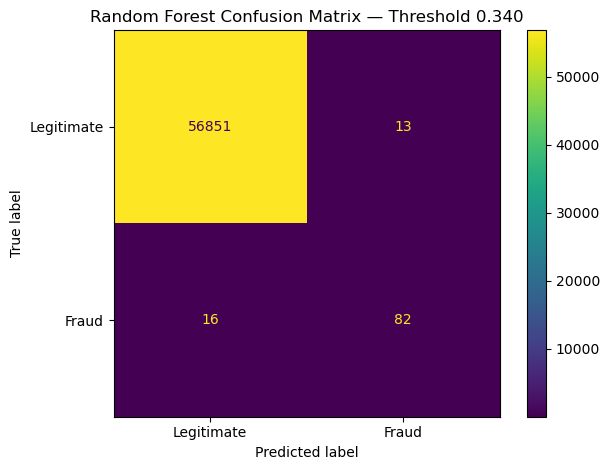

In [29]:
# ============================================================
# CONFUSION MATRIX — OPTIMIZED THRESHOLD
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_optimized_pred,
    display_labels=["Legitimate", "Fraud"],
    values_format="d"
)

plt.title(
    f"Random Forest Confusion Matrix — Threshold {rf_optimal_threshold:.3f}"
)
plt.tight_layout()
plt.show()

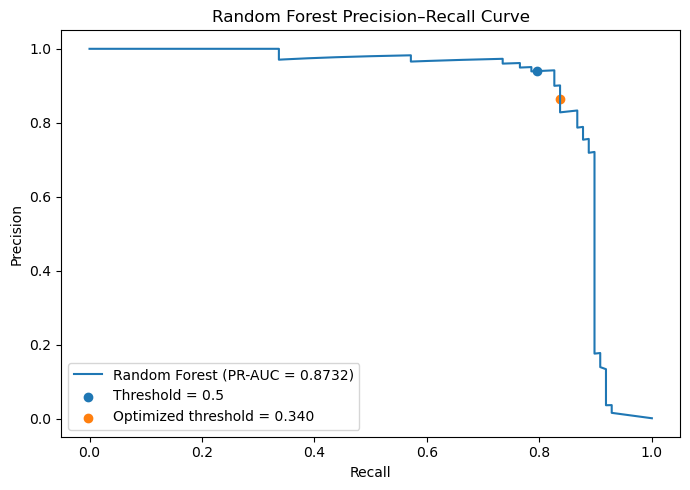

In [30]:
# ============================================================
# PRECISION–RECALL CURVE
# ============================================================

from sklearn.metrics import precision_recall_curve

rf_precision_curve, rf_recall_curve, _ = precision_recall_curve(
    y_test,
    rf_tuned_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    rf_recall_curve,
    rf_precision_curve,
    label=f"Random Forest (PR-AUC = {tuned_results['PR-AUC']:.4f})"
)

plt.scatter(
    tuned_results["Recall"],
    tuned_results["Precision"],
    label="Threshold = 0.5"
)

plt.scatter(
    rf_optimized_results["Recall"],
    rf_optimized_results["Precision"],
    label=f"Optimized threshold = {rf_optimal_threshold:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision–Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

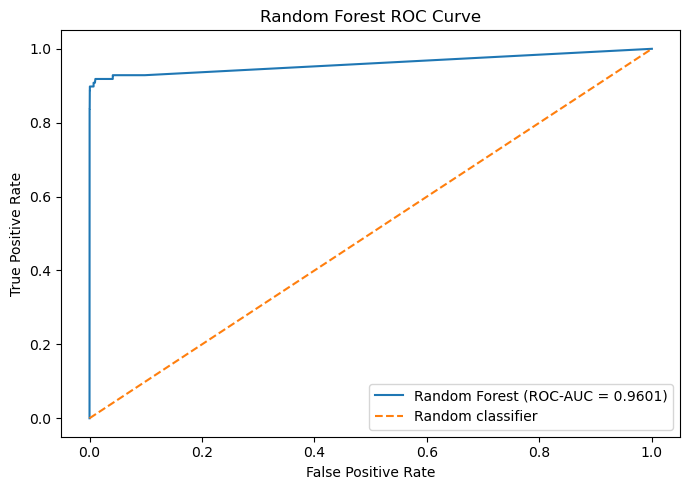

In [31]:
# ============================================================
# ROC CURVE
# ============================================================

from sklearn.metrics import roc_curve

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_tuned_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (ROC-AUC = {tuned_results['ROC-AUC']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# RANDOM FOREST FINAL SUMMARY TABLE
# ============================================================

rf_summary = pd.DataFrame({
    "Baseline RF (0.5)": [
        baseline_results["PR-AUC"],
        baseline_results["ROC-AUC"],
        baseline_results["Accuracy"],
        baseline_results["Precision"],
        baseline_results["Recall"],
        baseline_results["F1"]
    ],
    "Tuned RF (0.5)": [
        tuned_results["PR-AUC"],
        tuned_results["ROC-AUC"],
        tuned_results["Accuracy"],
        tuned_results["Precision"],
        tuned_results["Recall"],
        tuned_results["F1"]
    ],
    "Tuned RF (Optimized Threshold)": [
        rf_optimized_results["PR-AUC"],
        rf_optimized_results["ROC-AUC"],
        rf_optimized_results["Accuracy"],
        rf_optimized_results["Precision"],
        rf_optimized_results["Recall"],
        rf_optimized_results["F1"]
    ]
}, index=[
    "PR-AUC",
    "ROC-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
])

rf_summary.round(4)

,Baseline RF (0.5),Tuned RF (0.5),Tuned RF (Optimized Threshold)
PR-AUC,0.8675,0.8732,0.8732
ROC-AUC,0.9525,0.9601,0.9601
Accuracy,0.9996,0.9996,0.9995
Precision,0.9512,0.9398,0.8632
Recall,0.7959,0.7959,0.8367
F1,0.8667,0.8619,0.8497


In [33]:
rf_timing_summary = pd.DataFrame({
    "Metric": [
        "Training Time (seconds)",
        "Prediction Time (seconds)"
    ],
    "Random Forest": [
        rf_training_time,
        rf_prediction_time
    ]
})

rf_timing_summary

,Metric,Random Forest
0,Training Time (seconds),58.395580
1,Prediction Time (seconds),0.224351


In [34]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

# Get the fitted Random Forest classifier from the tuned pipeline
rf_classifier = rf_tuned_model.named_steps["classifier"]

# Get feature importances
rf_importances = rf_classifier.feature_importances_

# Reconstruct the feature order after preprocessing
processed_feature_names = scaled_features + pca_features

feature_importance_df = pd.DataFrame({
    "Feature": processed_feature_names,
    "Importance": rf_importances
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("TOP 15 RANDOM FOREST FEATURES")
print("-" * 40)
print(feature_importance_df.head(15))

TOP 15 RANDOM FOREST FEATURES
----------------------------------------
   Feature  Importance
0      V14    0.162246
1       V4    0.114543
2      V10    0.109295
3      V12    0.084013
4      V11    0.078401
5      V17    0.072493
6       V3    0.056501
7      V16    0.045532
8       V7    0.034618
9       V2    0.028615
10      V9    0.020207
11     V18    0.018759
12     V21    0.017669
13     V20    0.013539
14      V1    0.012905


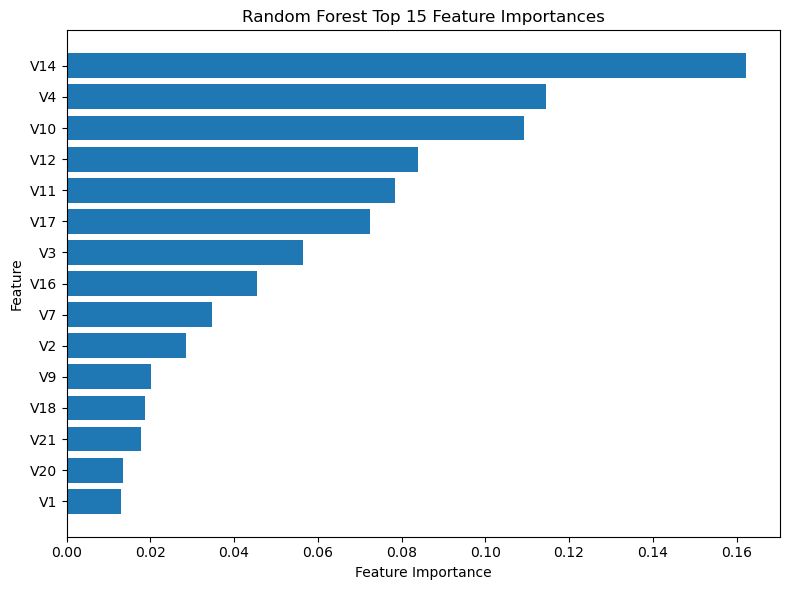

In [35]:
# ============================================================
# TOP FEATURE IMPORTANCE PLOT
# ============================================================

top_n = 15

top_features = feature_importance_df.head(top_n)

plt.figure(figsize=(8, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Top 15 Feature Importances")
plt.tight_layout()
plt.show()

## ANN Hyperparameter Tuning

The ANN development process explored multiple network architectures and
training configurations. To make the tuning process explicitly reproducible
within the final master notebook, the following randomized search evaluates
candidate hidden-layer structures, regularization strengths, batch sizes, and
learning rates using the shared five-fold stratified cross-validation framework.

RandomOverSampler is held fixed so that the ANN uses the same class-imbalance
treatment as Logistic Regression and Random Forest in the final standardized
comparison. Candidate models are ranked using PR-AUC (average precision).

In [36]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK — HYPERPARAMETER TUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPClassifier

ann_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("oversampler", RandomOverSampler(
        random_state=RANDOM_STATE
    )),
    ("classifier", MLPClassifier(
        max_iter=200,
        early_stopping=False,
        random_state=RANDOM_STATE
    ))
])

ann_param_distributions = {
    "classifier__hidden_layer_sizes": [
        (32,),
        (64,),
        (32, 16),
        (64, 32)
    ],
    "classifier__alpha": [
        0.0001,
        0.001,
        0.01
    ],
    "classifier__batch_size": [
        256,
        512
    ],
    "classifier__learning_rate_init": [
        0.0005,
        0.001,
        0.002
    ]
}

ann_random_search = RandomizedSearchCV(
    estimator=ann_tuning_pipeline,
    param_distributions=ann_param_distributions,
    n_iter=12,
    scoring="average_precision",
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("Starting ANN Randomized Search...")
ann_random_search.fit(X_train, y_train)

print("\nBEST ANN PARAMETERS")
print("-" * 40)
print(ann_random_search.best_params_)

print("\nBest CV PR-AUC:")
print(f"{ann_random_search.best_score_:.4f}")

Starting ANN Randomized Search...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

BEST ANN PARAMETERS
----------------------------------------
{'classifier__learning_rate_init': 0.001, 'classifier__hidden_layer_sizes': (32, 16), 'classifier__batch_size': 256, 'classifier__alpha': 0.001}

Best CV PR-AUC:
0.8143


In [37]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK — HYPERPARAMETER TUNING RESULTS
# ============================================================

ann_tuning_results = pd.DataFrame(
    ann_random_search.cv_results_
)[[
    "param_classifier__hidden_layer_sizes",
    "param_classifier__alpha",
    "param_classifier__batch_size",
    "param_classifier__learning_rate_init",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

ann_tuning_results = ann_tuning_results.rename(columns={
    "param_classifier__hidden_layer_sizes": "Hidden Layers",
    "param_classifier__alpha": "Alpha",
    "param_classifier__batch_size": "Batch Size",
    "param_classifier__learning_rate_init": "Learning Rate",
    "mean_test_score": "Mean CV PR-AUC",
    "std_test_score": "CV PR-AUC Std",
    "rank_test_score": "Rank"
})

ann_tuning_results = ann_tuning_results.sort_values("Rank")

print("TOP ANN TUNING RESULTS")
print("-" * 40)

ann_tuning_results.head(10).round(6)

TOP ANN TUNING RESULTS
----------------------------------------


,Hidden Layers,Alpha,Batch Size,Learning Rate,Mean CV PR-AUC,CV PR-AUC Std,Rank
11,"(32, 16)",0.0010,256,0.0010,0.814254,0.010694,1
4,"(64,)",0.0010,256,0.0010,0.805793,0.006309,2
10,"(64, 32)",0.0010,512,0.0020,0.803109,0.015463,3
8,"(32,)",0.0001,512,0.0005,0.802940,0.014147,4
0,"(64,)",0.0001,256,0.0010,0.802664,0.009135,5
7,"(64, 32)",0.0010,256,0.0010,0.801420,0.019893,6
1,"(32,)",0.0100,512,0.0020,0.800712,0.018199,7
5,"(32,)",0.0100,256,0.0020,0.800213,0.011752,8
2,"(32, 16)",0.0001,512,0.0005,0.798726,0.028254,9
6,"(64, 32)",0.0001,256,0.0010,0.798536,0.035510,10


### ANN Tuning Selection

The randomized search evaluated 12 candidate ANN configurations using
five-fold stratified cross-validation and PR-AUC as the optimization metric.
The highest-performing configuration achieved a mean CV PR-AUC of 0.8143
and used two hidden layers containing 32 and 16 neurons, an L2
regularization parameter (`alpha`) of 0.001, a batch size of 256, and an
initial learning rate of 0.001. This configuration was therefore selected
for subsequent cross-validation, final training, and held-out test evaluation.

In [38]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK — FINAL MODEL CONFIGURATION
# ============================================================

from sklearn.neural_network import MLPClassifier

ann_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("oversampler", RandomOverSampler(
        random_state=RANDOM_STATE
    )),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        alpha=0.001,
        batch_size=256,
        learning_rate_init=0.001,
        max_iter=200,
        early_stopping=False,
        random_state=RANDOM_STATE
    ))
])

print("ANN configuration:")
print(ann_pipeline)

ANN configuration:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('robust_scale',
                                                  RobustScaler(),
                                                  ['Time', 'Amount']),
                                                 ('pca_passthrough',
                                                  'passthrough',
                                                  ['V1', 'V2', 'V3', 'V4', 'V5',
                                                   'V6', 'V7', 'V8', 'V9',
                                                   'V10', 'V11', 'V12', 'V13',
                                                   'V14', 'V15', 'V16', 'V17',
                                                   'V18', 'V19', 'V20', 'V21',
                                                   'V22', 'V23', 'V24', 'V25',
                                                   'V26', 'V27', 'V28'])])),
                ('oversampler', RandomOverSampler(random_state

In [39]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK — 5-FOLD CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import cross_validate

print("Running ANN 5-fold stratified cross-validation...")

ann_cv_results = cross_validate(
    ann_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring="average_precision",
    return_estimator=True,
    n_jobs=-1
)

ann_cv_scores = ann_cv_results["test_score"]

print("\nANN CROSS-VALIDATION RESULTS")
print("-" * 45)
print(f"Mean CV PR-AUC: {ann_cv_scores.mean():.4f}")
print(f"CV PR-AUC std:  {ann_cv_scores.std():.4f}")

print("\nEpochs per fold:")
print([
    estimator.named_steps["classifier"].n_iter_
    for estimator in ann_cv_results["estimator"]
])

Running ANN 5-fold stratified cross-validation...

ANN CROSS-VALIDATION RESULTS
---------------------------------------------
Mean CV PR-AUC: 0.8143
CV PR-AUC std:  0.0107

Epochs per fold:
[31, 27, 39, 35, 35]


In [40]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK — FINAL FIT + DEFAULT THRESHOLD
# ============================================================

import time

ann_final_model = ann_pipeline

start_train = time.perf_counter()
ann_final_model.fit(X_train, y_train)
ann_training_time = time.perf_counter() - start_train

start_predict = time.perf_counter()
ann_test_proba = ann_final_model.predict_proba(X_test)[:, 1]
ann_prediction_time = time.perf_counter() - start_predict

ann_default_results, ann_default_pred = evaluate_classifier(
    y_test,
    ann_test_proba,
    threshold=0.5
)

print("ARTIFICIAL NEURAL NETWORK — DEFAULT THRESHOLD")
print("-" * 55)

for metric, value in ann_default_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ann_default_pred))

print("\nTiming:")
print(f"Training time:   {ann_training_time:.4f} seconds")
print(f"Prediction time: {ann_prediction_time:.4f} seconds")

ARTIFICIAL NEURAL NETWORK — DEFAULT THRESHOLD
-------------------------------------------------------
PR-AUC: 0.8248
ROC-AUC: 0.9645
Accuracy: 0.9986
Precision: 0.5724
Recall: 0.8469
F1: 0.6831

Confusion Matrix:
[[56802    62]
 [   15    83]]

Timing:
Training time:   34.3490 seconds
Prediction time: 0.0234 seconds


In [41]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK — OOF THRESHOLD SELECTION
# ============================================================

print("Generating ANN out-of-fold probabilities...")

ann_oof_proba = cross_val_predict(
    ann_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions complete.")
print(
    f"OOF PR-AUC: "
    f"{average_precision_score(y_train, ann_oof_proba):.4f}"
)
print(f"Number of OOF predictions: {len(ann_oof_proba):,}")

Generating ANN out-of-fold probabilities...
Out-of-fold predictions complete.
OOF PR-AUC: 0.8113
Number of OOF predictions: 227,845


In [42]:
# ============================================================
# SELECT ANN OPERATING THRESHOLD
# ============================================================

ann_optimal_threshold, ann_oof_precision, ann_oof_recall = (
    select_recall_constrained_threshold(
        y_train,
        ann_oof_proba,
        min_recall=0.80
    )
)

print("ARTIFICIAL NEURAL NETWORK THRESHOLD SELECTION")
print("-" * 55)
print("Selection rule: Maximum precision with recall >= 0.80")
print(f"Selected threshold: {ann_optimal_threshold:.6f}")
print(f"OOF precision at threshold: {ann_oof_precision:.4f}")
print(f"OOF recall at threshold:    {ann_oof_recall:.4f}")

ARTIFICIAL NEURAL NETWORK THRESHOLD SELECTION
-------------------------------------------------------
Selection rule: Maximum precision with recall >= 0.80
Selected threshold: 0.985084
OOF precision at threshold: 0.8360
OOF recall at threshold:    0.8020


In [43]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK — OPTIMIZED THRESHOLD EVALUATION
# ============================================================

ann_optimized_results, ann_optimized_pred = evaluate_classifier(
    y_test,
    ann_test_proba,
    threshold=ann_optimal_threshold
)

print("ARTIFICIAL NEURAL NETWORK — OPTIMIZED THRESHOLD")
print("-" * 60)
print(f"Threshold: {ann_optimal_threshold:.6f}")

for metric, value in ann_optimized_results.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ann_optimized_pred))

ARTIFICIAL NEURAL NETWORK — OPTIMIZED THRESHOLD
------------------------------------------------------------
Threshold: 0.985084
PR-AUC: 0.8248
ROC-AUC: 0.9645
Accuracy: 0.9992
Precision: 0.7547
Recall: 0.8163
F1: 0.7843

Confusion Matrix:
[[56838    26]
 [   18    80]]


In [44]:
# ============================================================
# ARTIFICIAL NEURAL NETWORK FINAL SUMMARY TABLE
# ============================================================

ann_summary = pd.DataFrame({
    "ANN (0.5)": [
        ann_default_results["PR-AUC"],
        ann_default_results["ROC-AUC"],
        ann_default_results["Accuracy"],
        ann_default_results["Precision"],
        ann_default_results["Recall"],
        ann_default_results["F1"]
    ],
    "ANN (Optimized Threshold)": [
        ann_optimized_results["PR-AUC"],
        ann_optimized_results["ROC-AUC"],
        ann_optimized_results["Accuracy"],
        ann_optimized_results["Precision"],
        ann_optimized_results["Recall"],
        ann_optimized_results["F1"]
    ]
}, index=[
    "PR-AUC",
    "ROC-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
])

ann_summary.round(4)

,ANN (0.5),ANN (Optimized Threshold)
PR-AUC,0.8248,0.8248
ROC-AUC,0.9645,0.9645
Accuracy,0.9986,0.9992
Precision,0.5724,0.7547
Recall,0.8469,0.8163
F1,0.6831,0.7843


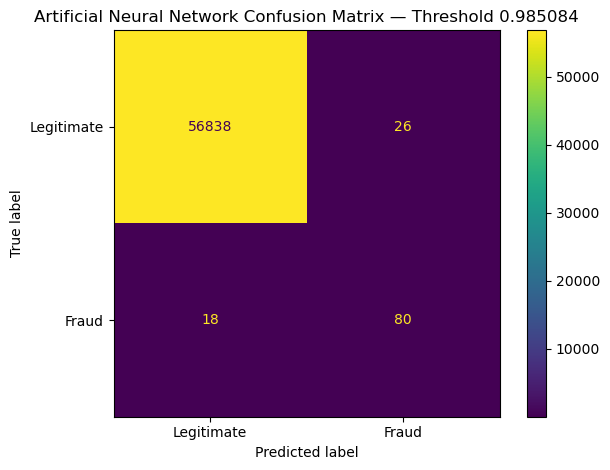

In [45]:
# ============================================================
# ANN CONFUSION MATRIX — OPTIMIZED THRESHOLD
# ============================================================

ConfusionMatrixDisplay.from_predictions(
    y_test,
    ann_optimized_pred,
    display_labels=["Legitimate", "Fraud"],
    values_format="d"
)

plt.title(
    f"Artificial Neural Network Confusion Matrix — "
    f"Threshold {ann_optimal_threshold:.6f}"
)

plt.tight_layout()
plt.show()

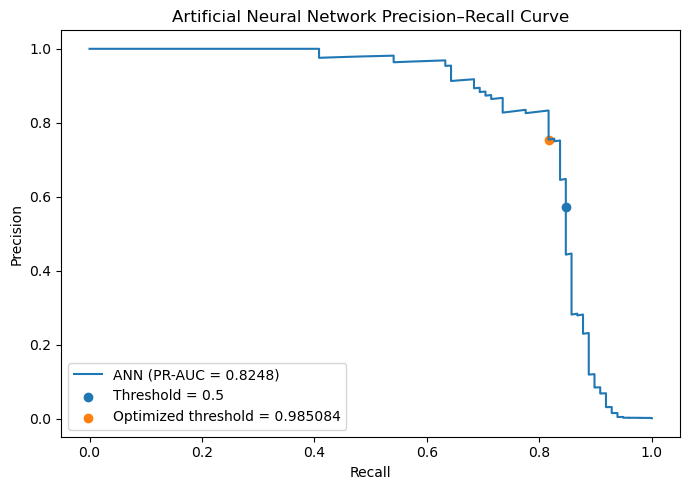

In [46]:
# ============================================================
# ANN PRECISION–RECALL CURVE
# ============================================================

ann_precision_test, ann_recall_test, _ = precision_recall_curve(
    y_test,
    ann_test_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    ann_recall_test,
    ann_precision_test,
    label=f"ANN (PR-AUC = {ann_default_results['PR-AUC']:.4f})"
)

plt.scatter(
    ann_default_results["Recall"],
    ann_default_results["Precision"],
    label="Threshold = 0.5"
)

plt.scatter(
    ann_optimized_results["Recall"],
    ann_optimized_results["Precision"],
    label=f"Optimized threshold = {ann_optimal_threshold:.6f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Artificial Neural Network Precision–Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

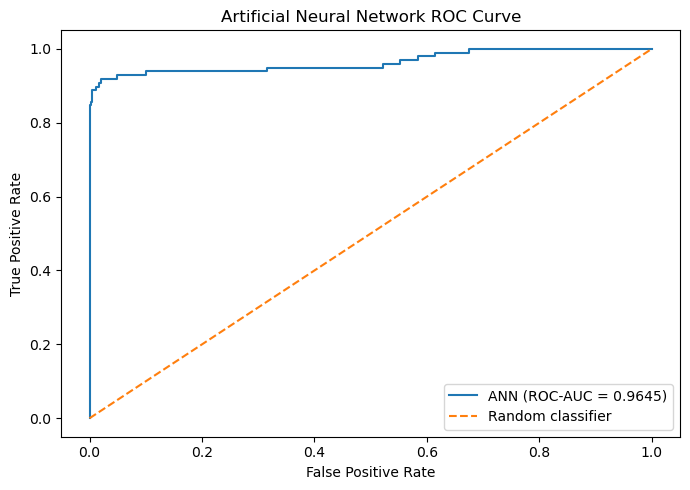

In [47]:
# ============================================================
# ANN ROC CURVE
# ============================================================

ann_fpr, ann_tpr, _ = roc_curve(
    y_test,
    ann_test_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    ann_fpr,
    ann_tpr,
    label=f"ANN (ROC-AUC = {ann_default_results['ROC-AUC']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Artificial Neural Network ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

# Comparative Analysis

The following analysis compares Logistic Regression, Random Forest, and the
Artificial Neural Network under the same train/test split, preprocessing strategy,
class-imbalance treatment, five-fold stratified cross-validation framework, and
evaluation metrics.

In [48]:
# ============================================================
# CROSS-MODEL COMPARISON — OPTIMIZED OPERATING POINTS
# ============================================================

model_comparison = pd.DataFrame({
    "Logistic Regression": [
        lr_optimized_results["PR-AUC"],
        lr_optimized_results["ROC-AUC"],
        lr_optimized_results["Accuracy"],
        lr_optimized_results["Precision"],
        lr_optimized_results["Recall"],
        lr_optimized_results["F1"],
        lr_optimal_threshold,
        lr_training_time,
        lr_prediction_time
    ],
    "Random Forest": [
        rf_optimized_results["PR-AUC"],
        rf_optimized_results["ROC-AUC"],
        rf_optimized_results["Accuracy"],
        rf_optimized_results["Precision"],
        rf_optimized_results["Recall"],
        rf_optimized_results["F1"],
        rf_optimal_threshold,
        rf_training_time,
        rf_prediction_time
    ],
    "Artificial Neural Network": [
        ann_optimized_results["PR-AUC"],
        ann_optimized_results["ROC-AUC"],
        ann_optimized_results["Accuracy"],
        ann_optimized_results["Precision"],
        ann_optimized_results["Recall"],
        ann_optimized_results["F1"],
        ann_optimal_threshold,
        ann_training_time,
        ann_prediction_time
    ]
}, index=[
    "PR-AUC",
    "ROC-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Selected Threshold",
    "Training Time (s)",
    "Prediction Time (s)"
])

model_comparison.round(6)

,Logistic Regression,Random Forest,Artificial Neural Network
PR-AUC,0.711060,0.873237,0.824811
ROC-AUC,0.971996,0.960134,0.964450
Accuracy,0.999105,0.999491,0.999228
Precision,0.700855,0.863158,0.754717
Recall,0.836735,0.836735,0.816327
F1,0.762791,0.849741,0.784314
Selected Threshold,0.999801,0.339881,0.985084
Training Time (s),1.633840,58.395580,34.349022
Prediction Time (s),0.009640,0.224351,0.023436


In [49]:
# ============================================================
# CROSS-MODEL COMPARISON — DEFAULT THRESHOLD 0.5
# ============================================================

default_threshold_comparison = pd.DataFrame({
    "Logistic Regression": [
        lr_default_results["PR-AUC"],
        lr_default_results["ROC-AUC"],
        lr_default_results["Accuracy"],
        lr_default_results["Precision"],
        lr_default_results["Recall"],
        lr_default_results["F1"]
    ],
    "Random Forest": [
        tuned_results["PR-AUC"],
        tuned_results["ROC-AUC"],
        tuned_results["Accuracy"],
        tuned_results["Precision"],
        tuned_results["Recall"],
        tuned_results["F1"]
    ],
    "Artificial Neural Network": [
        ann_default_results["PR-AUC"],
        ann_default_results["ROC-AUC"],
        ann_default_results["Accuracy"],
        ann_default_results["Precision"],
        ann_default_results["Recall"],
        ann_default_results["F1"]
    ]
}, index=[
    "PR-AUC",
    "ROC-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
])

default_threshold_comparison.round(4)

,Logistic Regression,Random Forest,Artificial Neural Network
PR-AUC,0.7111,0.8732,0.8248
ROC-AUC,0.9720,0.9601,0.9645
Accuracy,0.9757,0.9996,0.9986
Precision,0.0613,0.9398,0.5724
Recall,0.9184,0.7959,0.8469
F1,0.1149,0.8619,0.6831


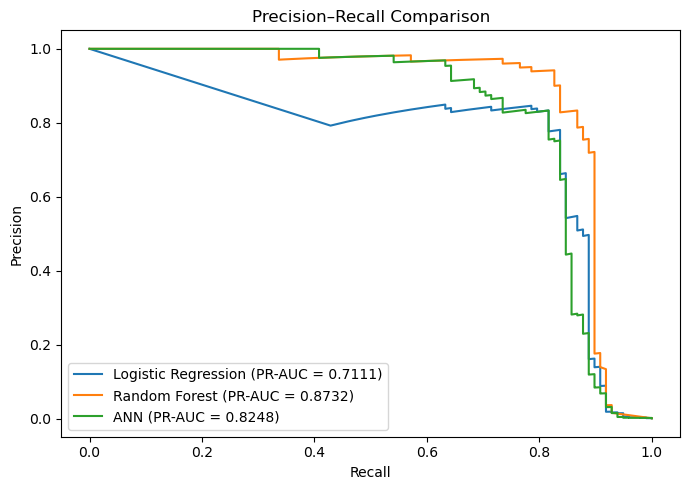

In [50]:
# ============================================================
# COMBINED PRECISION–RECALL CURVE
# ============================================================

plt.figure(figsize=(7, 5))

plt.plot(
    lr_recall_test,
    lr_precision_test,
    label=f"Logistic Regression (PR-AUC = {lr_default_results['PR-AUC']:.4f})"
)

plt.plot(
    rf_recall_curve,
    rf_precision_curve,
    label=f"Random Forest (PR-AUC = {tuned_results['PR-AUC']:.4f})"
)

plt.plot(
    ann_recall_test,
    ann_precision_test,
    label=f"ANN (PR-AUC = {ann_default_results['PR-AUC']:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Comparison")
plt.legend()
plt.tight_layout()
plt.show()

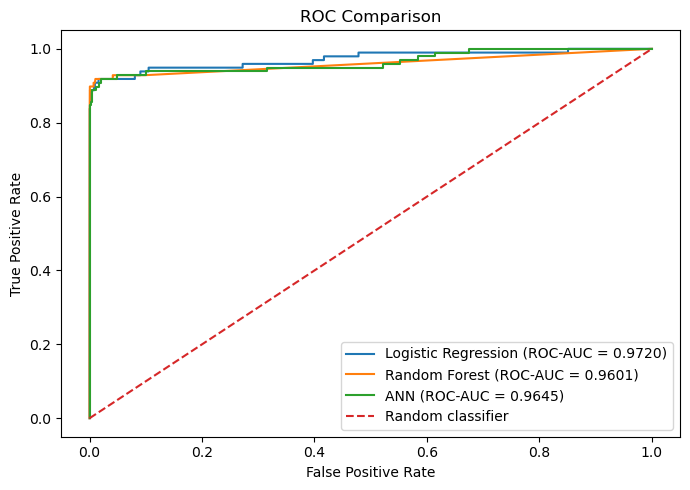

In [51]:
# ============================================================
# COMBINED ROC CURVE
# ============================================================

plt.figure(figsize=(7, 5))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (ROC-AUC = {lr_default_results['ROC-AUC']:.4f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (ROC-AUC = {tuned_results['ROC-AUC']:.4f})"
)

plt.plot(
    ann_fpr,
    ann_tpr,
    label=f"ANN (ROC-AUC = {ann_default_results['ROC-AUC']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Comparison")
plt.legend()
plt.tight_layout()
plt.show()